In [2]:
# load a synthetic 3D sample made by gen_pof3d.py (python gen_pof3d.py --n 6 --out sample3d)

import json
import pandas as pd
from pathlib import Path
import numpy as np

print(Path.cwd())
data = Path("sample3d")
name = "pof_00000"
df = pd.read_csv(data / "centerlines" / f"{name}.csv")
meta = {m["name"]: m for m in json.load(open(data / "meta.json"))}[name]
# columns: s_norm, X/Y/Z_m (world, z up, clamp at origin), tx/ty/tz (unit tangent),
#          curvature_per_m, twist_per_m, then u/v [px] and z [m] depth in camera 0 and 1
# 600 rows, clamp (s_norm=0) to tip (s_norm=1)

print(meta["fiber"], f'L={meta["length_m"]:.3f} m', meta["rig"], "tip force [N]:", np.round(meta["tip_force_N"], 5))
df.head()

c:\Users\alagi\shape-sensing\sw
jacketed_POF L=0.340 m multiview tip force [N]: [-0.0069  -0.03929 -0.02309]


,s_norm,X_m,Y_m,Z_m,tx,ty,tz,curvature_per_m,twist_per_m,u0_px,v0_px,z0_m,u1_px,v1_px,z1_m
0,0.000000,2.289138e-25,4.301955e-25,-1.309539e-24,-0.029667,0.037446,-0.998858,10.692561,6.565111e-11,390.102128,118.560681,0.360155,373.337458,191.246734,0.521347
1,0.001669,-1.710304e-05,1.956773e-05,-5.674284e-04,-0.030551,0.031458,-0.999038,10.628610,6.165229e-11,390.111169,119.932503,0.360150,373.290911,192.200210,0.521360
2,0.003339,-3.470640e-05,3.574407e-05,-1.134948e-03,-0.031429,0.025505,-0.999181,10.564985,6.547204e-11,390.124925,121.306614,0.360148,373.248432,193.153198,0.521371
3,0.005008,-5.280651e-05,4.854871e-05,-1.702539e-03,-0.032300,0.019586,-0.999286,10.501687,6.116408e-11,390.143365,122.682914,0.360150,373.209998,194.105678,0.521380
4,0.006678,-7.139981e-05,5.800143e-05,-2.270179e-03,-0.033165,0.013702,-0.999356,10.438715,6.489700e-11,390.166460,124.061307,0.360154,373.175585,195.057630,0.521387


                X_m         Y_m           Z_m  curvature_per_m
count  6.000000e+02  600.000000  6.000000e+02     6.000000e+02
mean  -1.777935e-02   -0.086596 -1.377250e-01     2.905563e+00
std    1.228883e-02    0.065521  7.086888e-02     2.733662e+00
min   -4.044137e-02   -0.210693 -2.491276e-01     1.485648e-18
25%   -2.837747e-02   -0.142936 -1.991477e-01     8.191370e-01
50%   -1.680118e-02   -0.078903 -1.444285e-01     1.857943e+00
75%   -6.486952e-03   -0.024941 -7.976424e-02     4.300192e+00
max    2.289138e-25    0.000067 -1.309539e-24     1.069256e+01


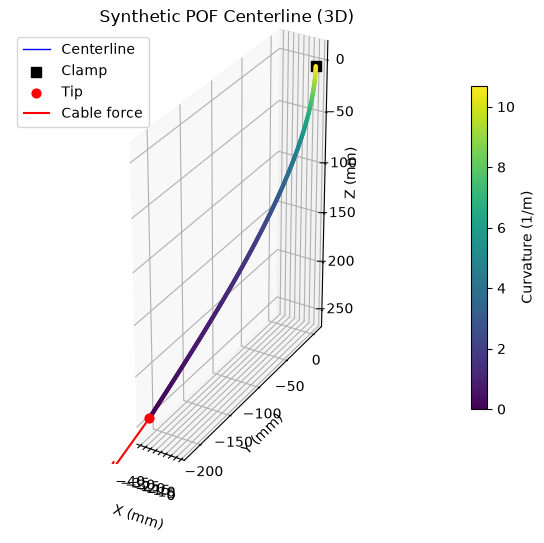

In [3]:
# 3D shape reconstruction plot
import matplotlib.pyplot as plt

X = df[["X_m", "Y_m", "Z_m"]].to_numpy() * 1e3          # mm
F = np.array(meta["tip_force_N"])

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection="3d")
p = ax.scatter(*X.T, c=df["curvature_per_m"], cmap="viridis", s=4)
ax.plot(*X.T, color="blue", lw=1, label="Centerline")
ax.scatter(*X[0], color="k", s=60, marker="s", label="Clamp")
ax.scatter(*X[-1], color="r", s=40, label="Tip")
if np.linalg.norm(F) > 0:                                # cable pull direction at the tip
    ax.quiver(*X[-1], *(F / np.linalg.norm(F) * 0.2 * meta["length_m"] * 1e3), color="r", label="Cable force")
ax.set_title("Synthetic POF Centerline (3D)")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_zlabel("Z (mm)")
ax.set_aspect("equal")
fig.colorbar(p, ax=ax, shrink=0.6, label="Curvature (1/m)")
ax.legend()
print(df[["X_m", "Y_m", "Z_m", "curvature_per_m"]].describe())

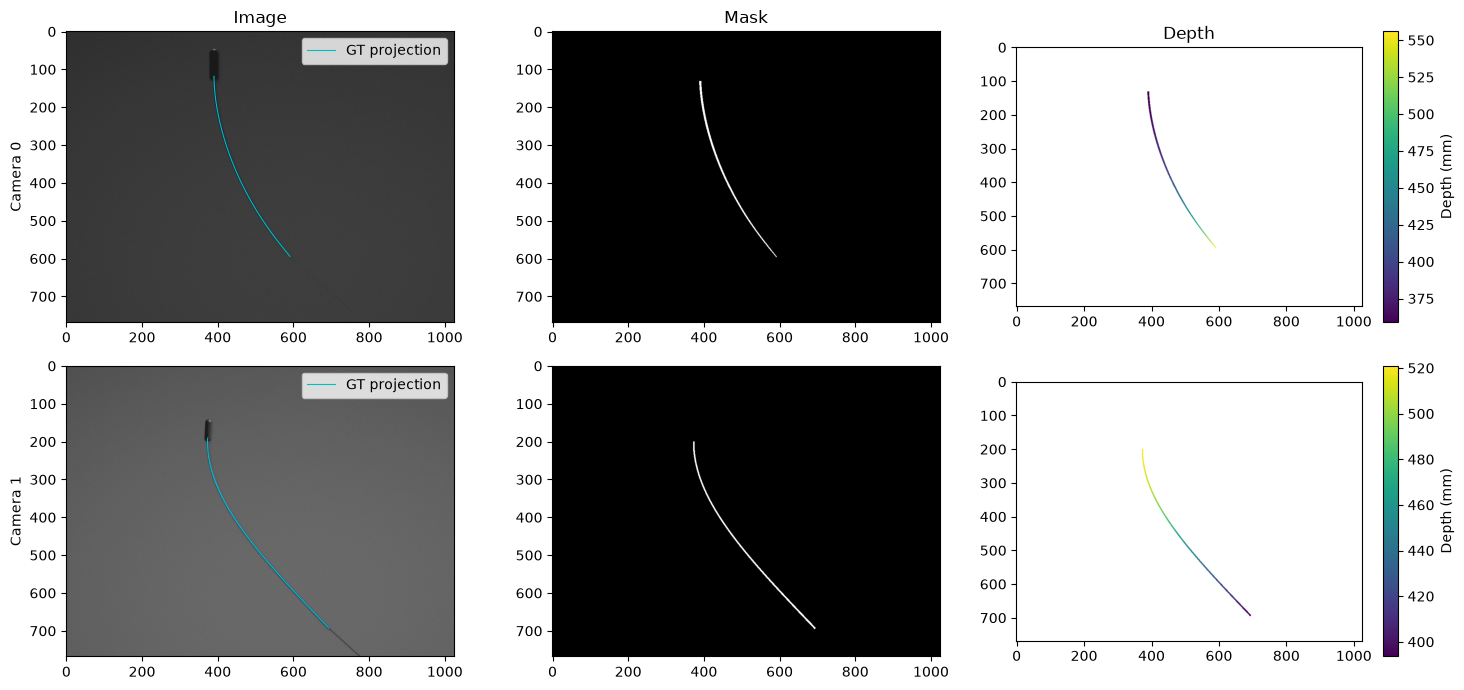

In [4]:
# camera views: image with the GT centerline projected on top, mask, and depth map
from PIL import Image

fig, axs = plt.subplots(2, 3, figsize=(15, 7))
for c in range(2):
    img = Image.open(data / "images" / f"{name}_c{c}.png")
    mask = np.array(Image.open(data / "masks" / f"{name}_c{c}.png"))
    depth = np.array(Image.open(data / "depth" / f"{name}_c{c}.png")) * 1e-4   # 0.1 mm units -> m
    axs[c, 0].imshow(img)
    axs[c, 0].plot(df[f"u{c}_px"], df[f"v{c}_px"], "c-", lw=0.8, label="GT projection")
    axs[c, 0].legend()
    axs[c, 1].imshow(mask, cmap="gray")
    d = axs[c, 2].imshow(np.where(depth > 0, depth * 1e3, np.nan), cmap="viridis")
    fig.colorbar(d, ax=axs[c, 2], label="Depth (mm)")
    axs[c, 0].set_ylabel(f"Camera {c}")
for a, t in zip(axs[0], ["Image", "Mask", "Depth"]):
    a.set_title(t)
plt.tight_layout()

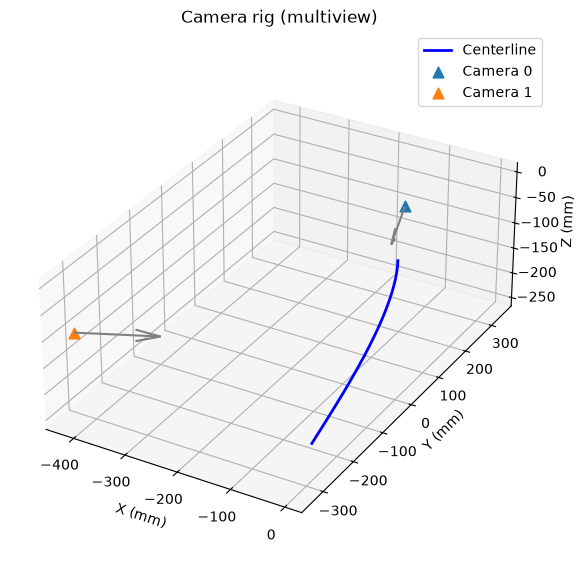

In [5]:
# rig layout: camera centres and viewing directions around the fiber
cams = meta["cameras"]

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection="3d")
ax.plot(*X.T, color="blue", lw=2, label="Centerline")
for c, cam in enumerate(cams):
    R, t = np.array(cam["R"]), np.array(cam["t"])
    C = -R.T @ t * 1e3                                   # camera centre in world (mm)
    ax.scatter(*C, s=60, marker="^", label=f"Camera {c}")
    ax.quiver(*C, *(R[2] * 0.3 * np.linalg.norm(C - X.mean(0))), color="gray")   # optical axis
ax.set_title(f'Camera rig ({meta["rig"]})')
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_zlabel("Z (mm)")
ax.set_aspect("equal")
ax.legend()

max error: 4.83e-13 mm


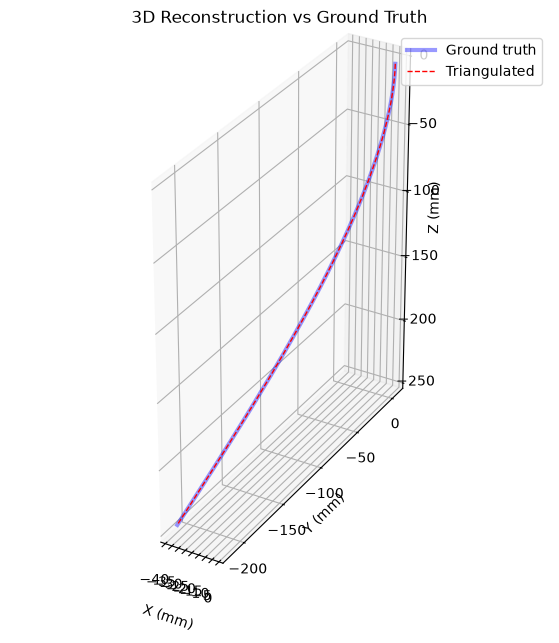

In [6]:
# sanity check: triangulate the GT 2D projections from both cameras back to 3D
# (later: replace uv0/uv1 with centerlines extracted from the masks)
from gen_pof3d import triangulate

P = [np.array(cam["K"]) @ np.column_stack([cam["R"], cam["t"]]) for cam in cams]
uv0 = df[["u0_px", "v0_px"]].to_numpy()
uv1 = df[["u1_px", "v1_px"]].to_numpy()
X_rec = triangulate(P[0], P[1], uv0, uv1) * 1e3

fig = plt.figure(figsize=(7, 7))
ax = fig.add_subplot(projection="3d")
ax.plot(*X.T, color="blue", lw=3, alpha=0.4, label="Ground truth")
ax.plot(*X_rec.T, "r--", lw=1, label="Triangulated")
ax.set_title("3D Reconstruction vs Ground Truth")
ax.set_xlabel("X (mm)")
ax.set_ylabel("Y (mm)")
ax.set_zlabel("Z (mm)")
ax.set_aspect("equal")
ax.legend()
print(f"max error: {np.abs(X_rec - X).max():.2e} mm")